# PPO (Proximal Policy Optimization) Notebook

In [1]:
import sys
sys.path.append("../../RL Policy Sparsification")

In [2]:
import gym, warnings, os, torch, random, gc, json
import numpy as np
import pandas as pd
from models import PolicyNet, SparsePolicyNet
from rl_utils.ppo import PPOTrainer, train
from  utils import (
    xavier_init_weights, 
    save_model_params, 
    plot_train_performance, 
    plot_result_dataframe,
    run_evaluation,
)
from typing import Union, Optional

warnings.filterwarnings("ignore")
os.environ["ENV_SEED"] = "3407"
RENDER_MODE_ON_EVAL = None
torch.set_default_dtype(torch.float32)

In [3]:
SEED = int(os.environ["ENV_SEED"])
random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed(SEED)
np.random.seed(SEED)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

In [4]:
policy_lr = 3e-4
value_lr = 1e-3

gamma = 0.99
lambda_ = 0.99
epsilon = 0.2
episodes = 4_000
entropy_coef = 0.01
n_policy_train_steps = 40
n_value_train_steps = 40
hidden_size = 128
max_episode_reward = 200
max_rollout_steps = 500

env_name = "LunarLander-v2"
train_env = gym.make(env_name)
results_dir = "../sparsification_results"

observation_space = train_env.observation_space._shape[0]
action_space = train_env.action_space.n

sparsity_penalty_coefs = np.array([1e-05, 5e-5, 1e-4, 5e-4, 1e-3, 5e-3, 1e-2, 5e-2, 1e-1, 5e-1])

REWARDS_DICT = dict()

In [5]:
def run_train(
        policy_agent: Union[PolicyNet, SparsePolicyNet], 
        value_agent: Union[PolicyNet, SparsePolicyNet],
        policy_optimizer: torch.optim.Optimizer,
        value_optimizer: torch.optim.Optimizer,
        policy_weights_filename: Optional[str]=None,
        save_best_weights: bool=True,
        sparse_penalty_coef: Optional[float]=None,
        plot_performance: bool=True,
    ):

    label = "dense"
    if isinstance(policy_agent, SparsePolicyNet):
        assert sparse_penalty_coef is not None
        label = f"sparse({sparse_penalty_coef})"

    if save_best_weights:
        assert policy_weights_filename is not None
    
    train_env = gym.make(env_name)
    ppo = PPOTrainer(
        policy_agent,
        value_agent, 
        policy_optimizer, 
        value_optimizer, 
        epsilon=epsilon, 
        entropy_coef=entropy_coef, 
        n_policy_train_steps=n_policy_train_steps, 
        n_value_train_steps=n_value_train_steps, 
        sparse_penalty_coef=sparse_penalty_coef,
    )

    os.makedirs("../params", exist_ok=True)

    try:
        train_performance, best_rewards = train(
            train_env, 
            ppo, 
            n_episodes=episodes, 
            gamma=gamma, 
            lambda_=lambda_, 
            max_episode_reward=max_episode_reward,
            max_rollout_steps=max_rollout_steps,
            continue_after_max_reward=False,
            policy_weights_filename=policy_weights_filename,
            save_best_weights=save_best_weights,
            verbose=False,
            close_env=True,
        )
        
        REWARDS_DICT[label] = train_performance["rewards"]
        if plot_performance:
            plot_train_performance(train_performance, best_rewards)

        convergence_steps = len(train_performance["rewards"])
        return convergence_steps
    
    except KeyboardInterrupt:
        train_env.close()

## Train and Evaluate Dense Policy

100%|██████████| 4000/4000 [1:37:38<00:00,  1.46s/it]


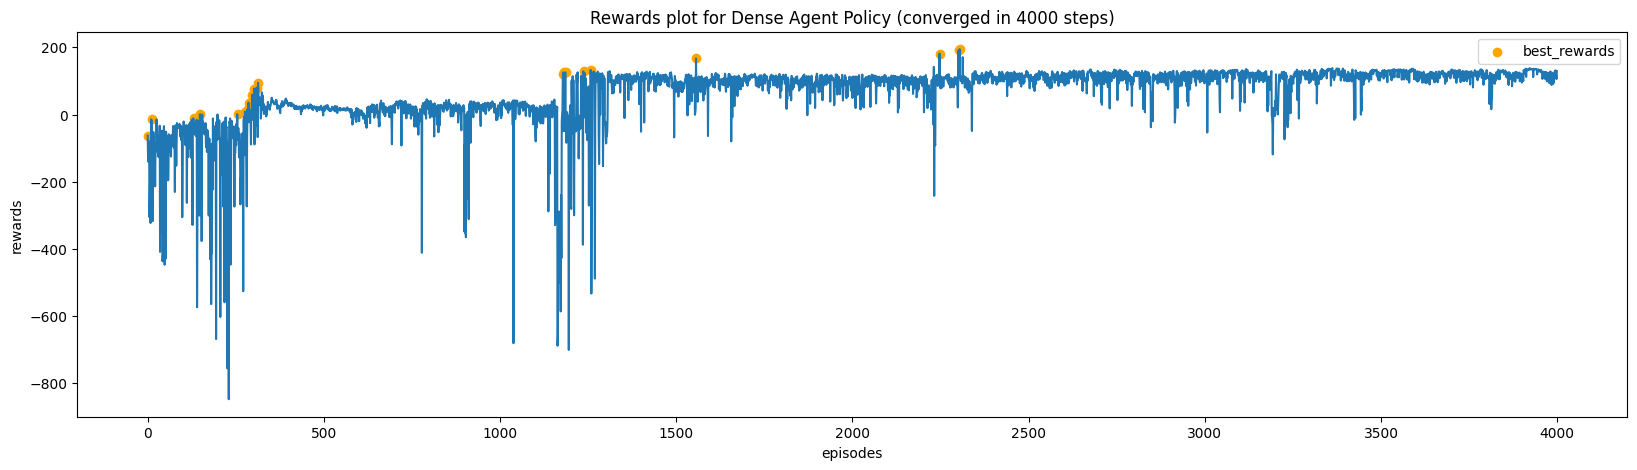

Evaluation reward of policy: 215.05906366186997
Average entropy of policy: 0.0138842


(215.05906366186997, 0.013884229558885838)

In [6]:
dense_policy_agent = PolicyNet(observation_space, action_space, hidden_size)
dense_policy_agent.to(os.getenv("DEVICE"))
dense_value_agent = PolicyNet(observation_space, 1, hidden_size)
dense_value_agent.to(os.getenv("DEVICE"))

dense_policy_agent.apply(xavier_init_weights)
dense_value_agent.apply(xavier_init_weights)

dense_policy_optimizer = torch.optim.Adam(dense_policy_agent.parameters(), lr=policy_lr)
dense_value_optimizer = torch.optim.Adam(dense_value_agent.parameters(), lr=value_lr)
policy_weights_filename = f"{env_name}_PPO_dense_policy_agent.pth.tar"

run_train(
    dense_policy_agent, 
    dense_value_agent, 
    dense_policy_optimizer, 
    dense_value_optimizer, 
    policy_weights_filename, 
    plot_performance=True
)


dense_policy_agent.load_state_dict(torch.load(os.path.join(f"../params/{policy_weights_filename}")))
run_evaluation(gym.make(env_name, render_mode=RENDER_MODE_ON_EVAL), dense_policy_agent, verbose=True)

## Train and Evaluate Sparse Policy Against Different Sparsity Coefficents

Training sparse policy with sparsity coef: 1e-05



  4%|▍         | 160/4000 [01:35<38:20,  1.67it/s]  


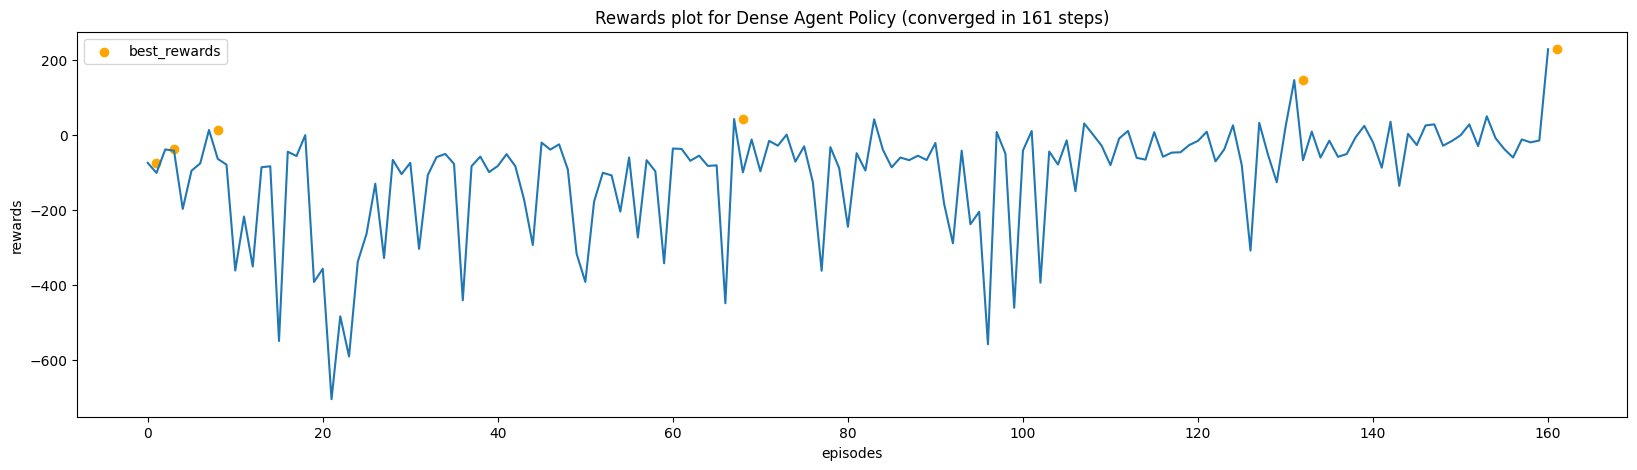

Training sparse policy with sparsity coef: 5e-05



 56%|█████▌    | 2233/4000 [1:21:06<1:04:11,  2.18s/it]


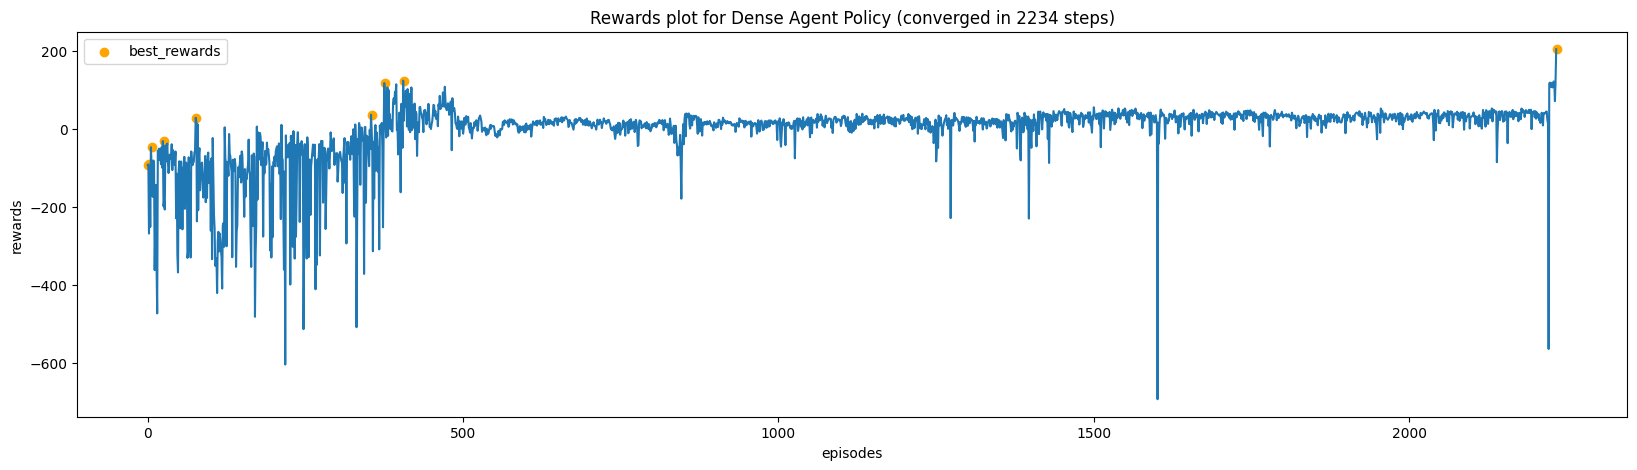

Training sparse policy with sparsity coef: 0.0001



 78%|███████▊  | 3120/4000 [1:50:39<31:12,  2.13s/it]  


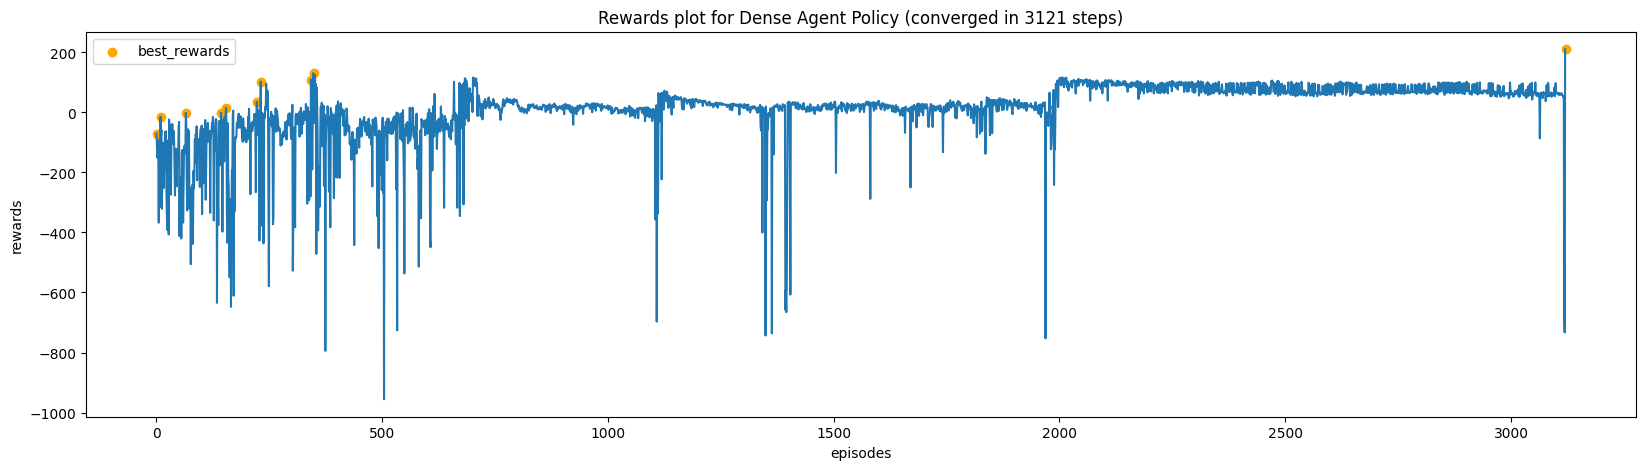

Training sparse policy with sparsity coef: 0.0005



100%|██████████| 4000/4000 [31:43<00:00,  2.10it/s] 


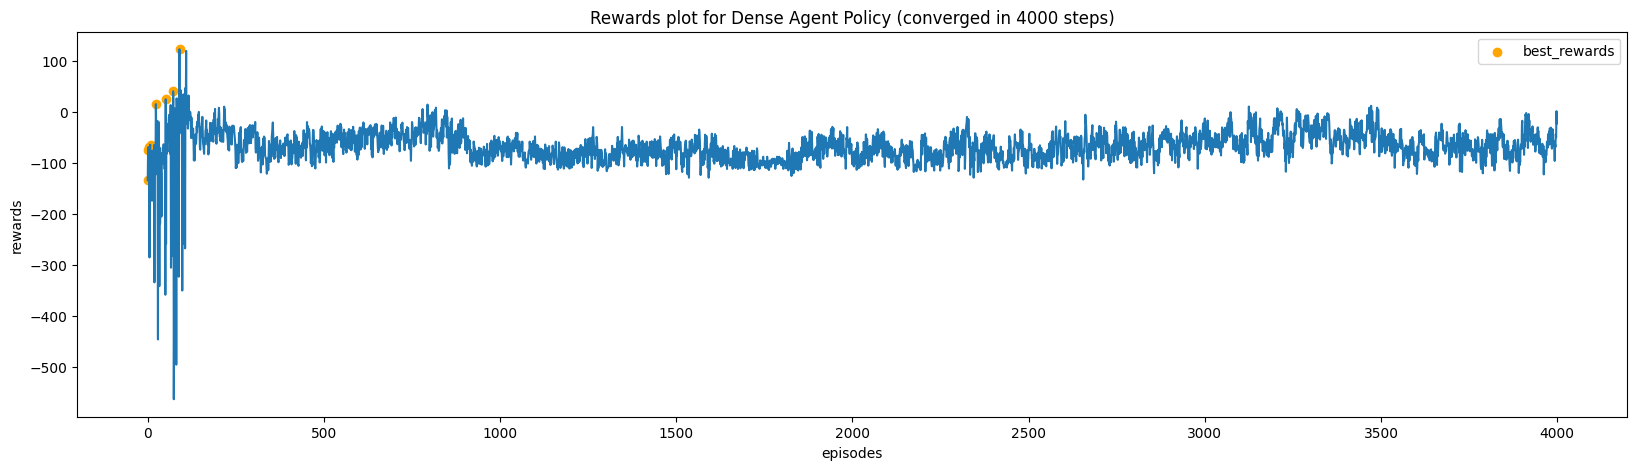

Training sparse policy with sparsity coef: 0.001



100%|██████████| 4000/4000 [2:21:29<00:00,  2.12s/it]  


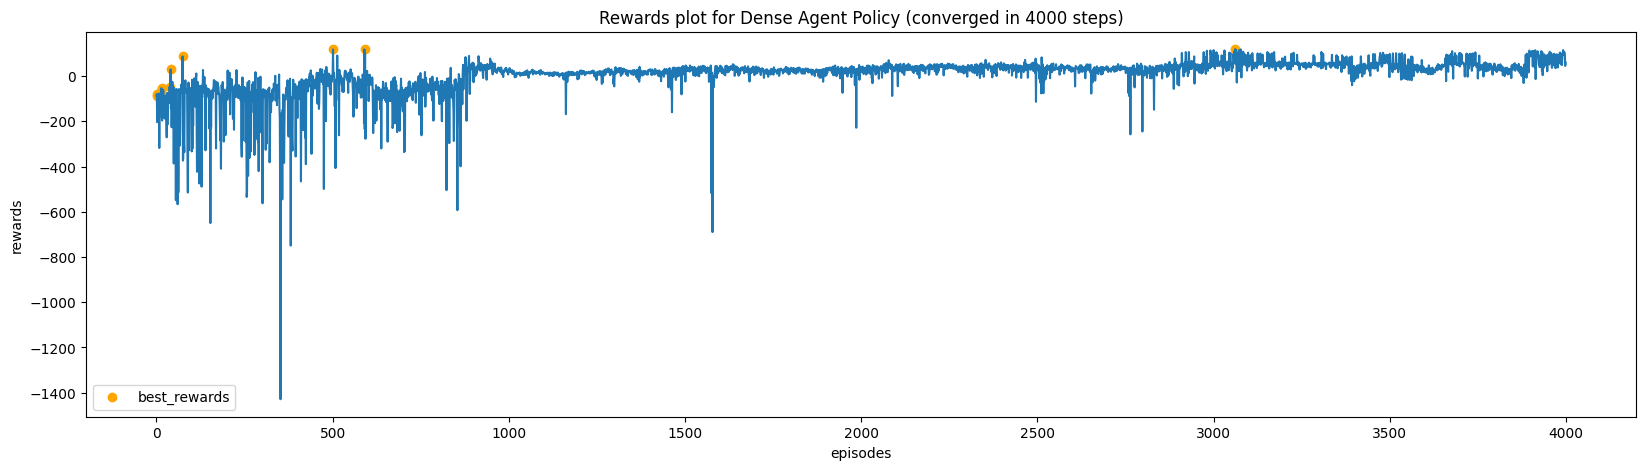

Training sparse policy with sparsity coef: 0.005



 12%|█▏        | 476/4000 [07:27<55:10,  1.06it/s]  


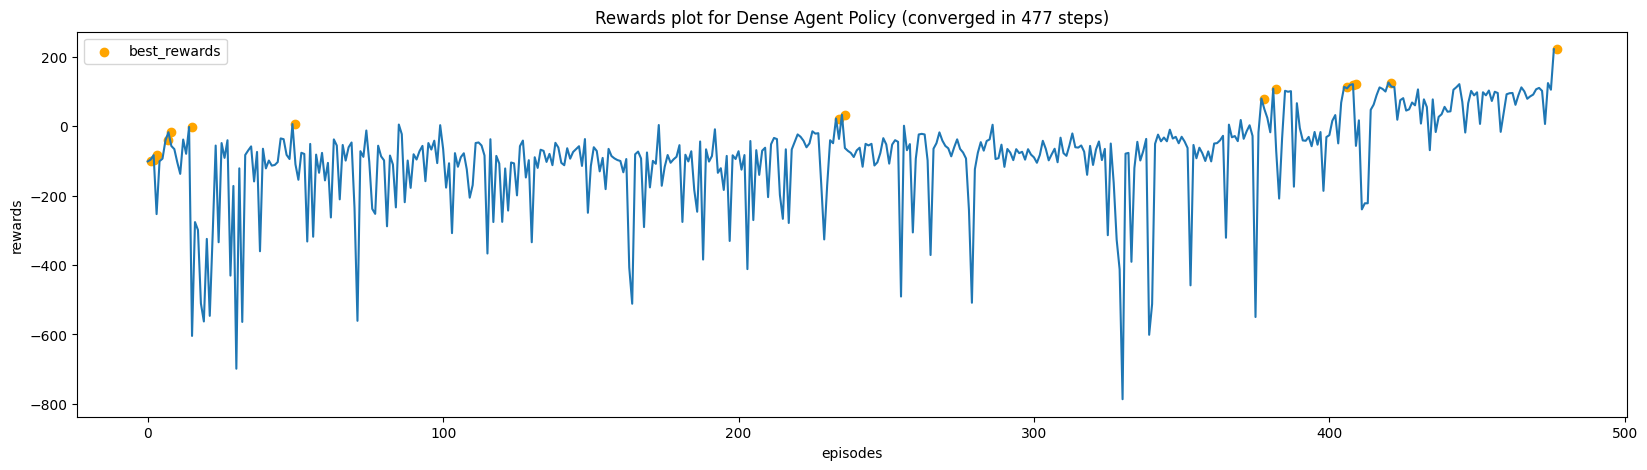

Training sparse policy with sparsity coef: 0.01



 84%|████████▍ | 3379/4000 [2:09:24<23:46,  2.30s/it]  


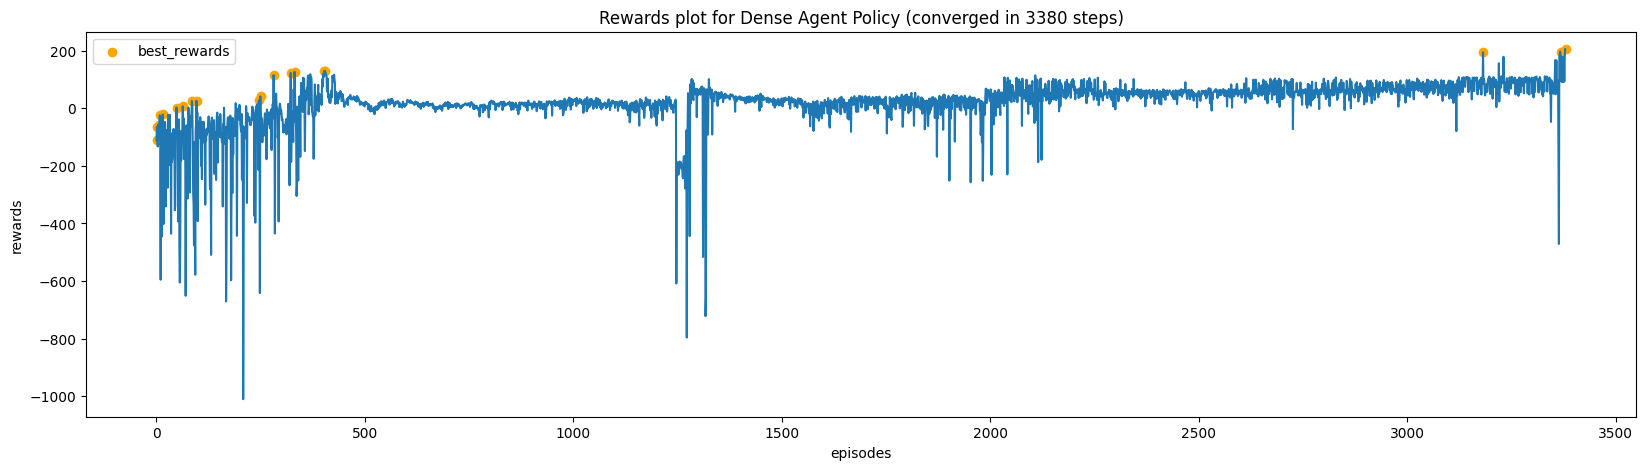

Training sparse policy with sparsity coef: 0.05



100%|██████████| 4000/4000 [2:34:36<00:00,  2.32s/it]  


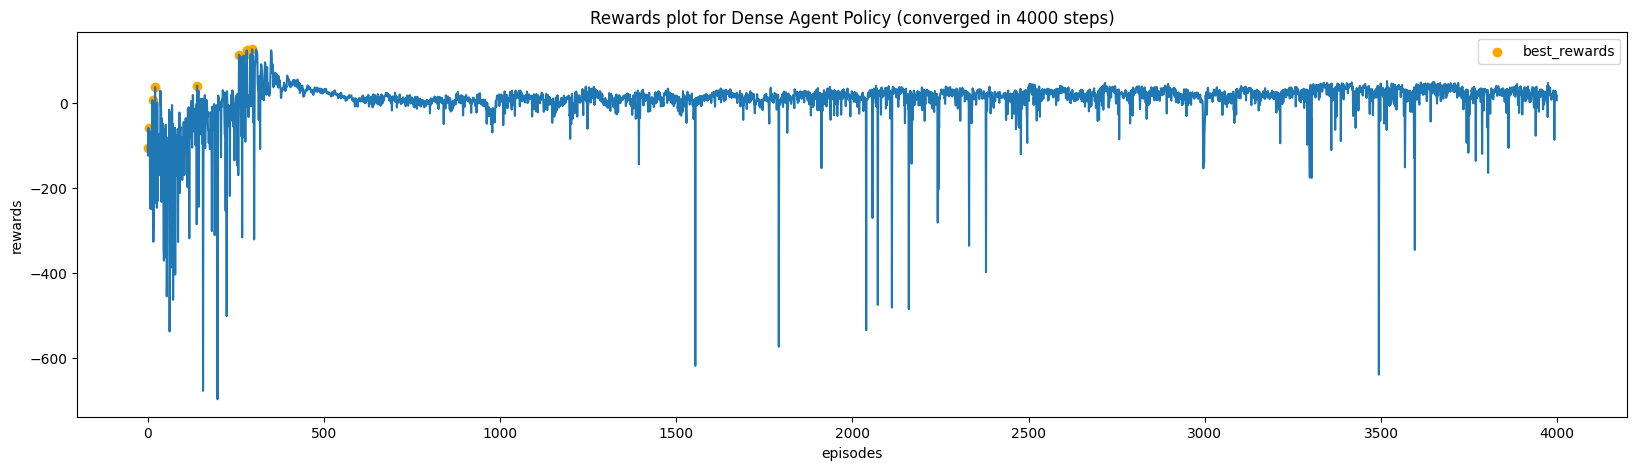

Training sparse policy with sparsity coef: 0.1



100%|██████████| 4000/4000 [2:24:09<00:00,  2.16s/it]  


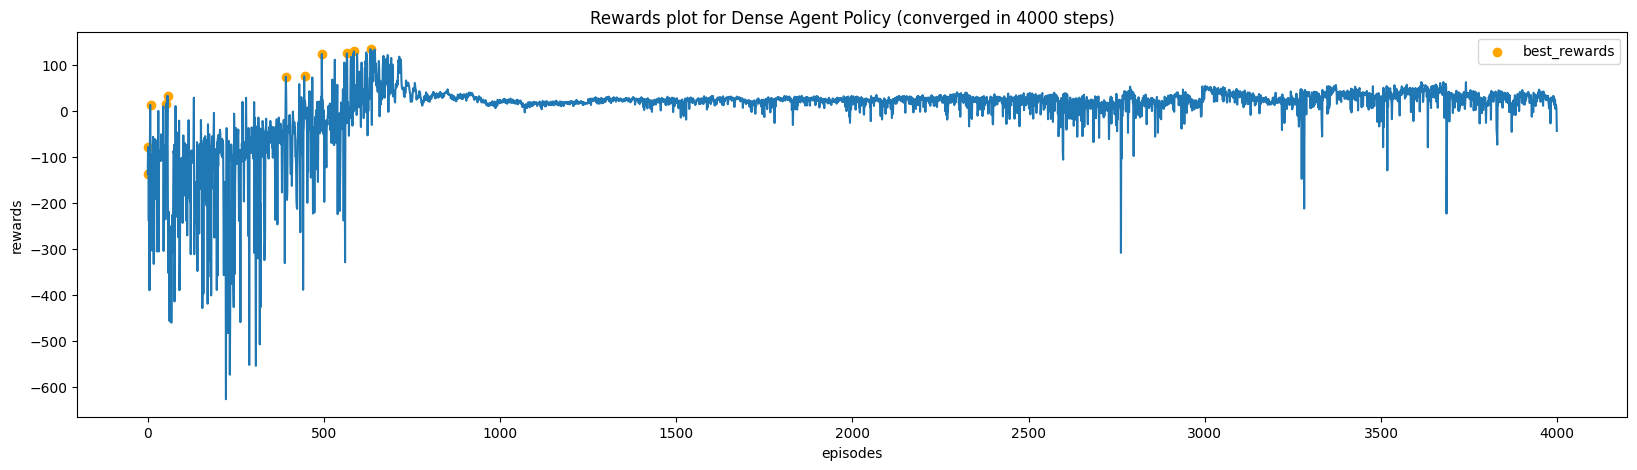

Training sparse policy with sparsity coef: 0.5



100%|██████████| 4000/4000 [2:35:04<00:00,  2.33s/it]  


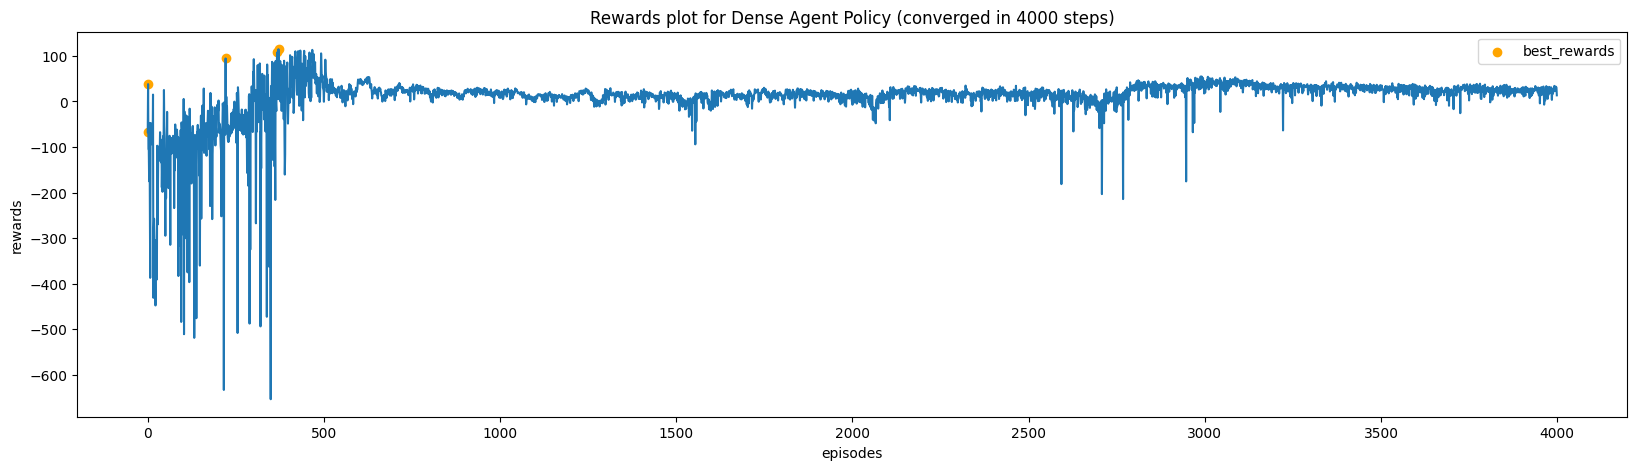

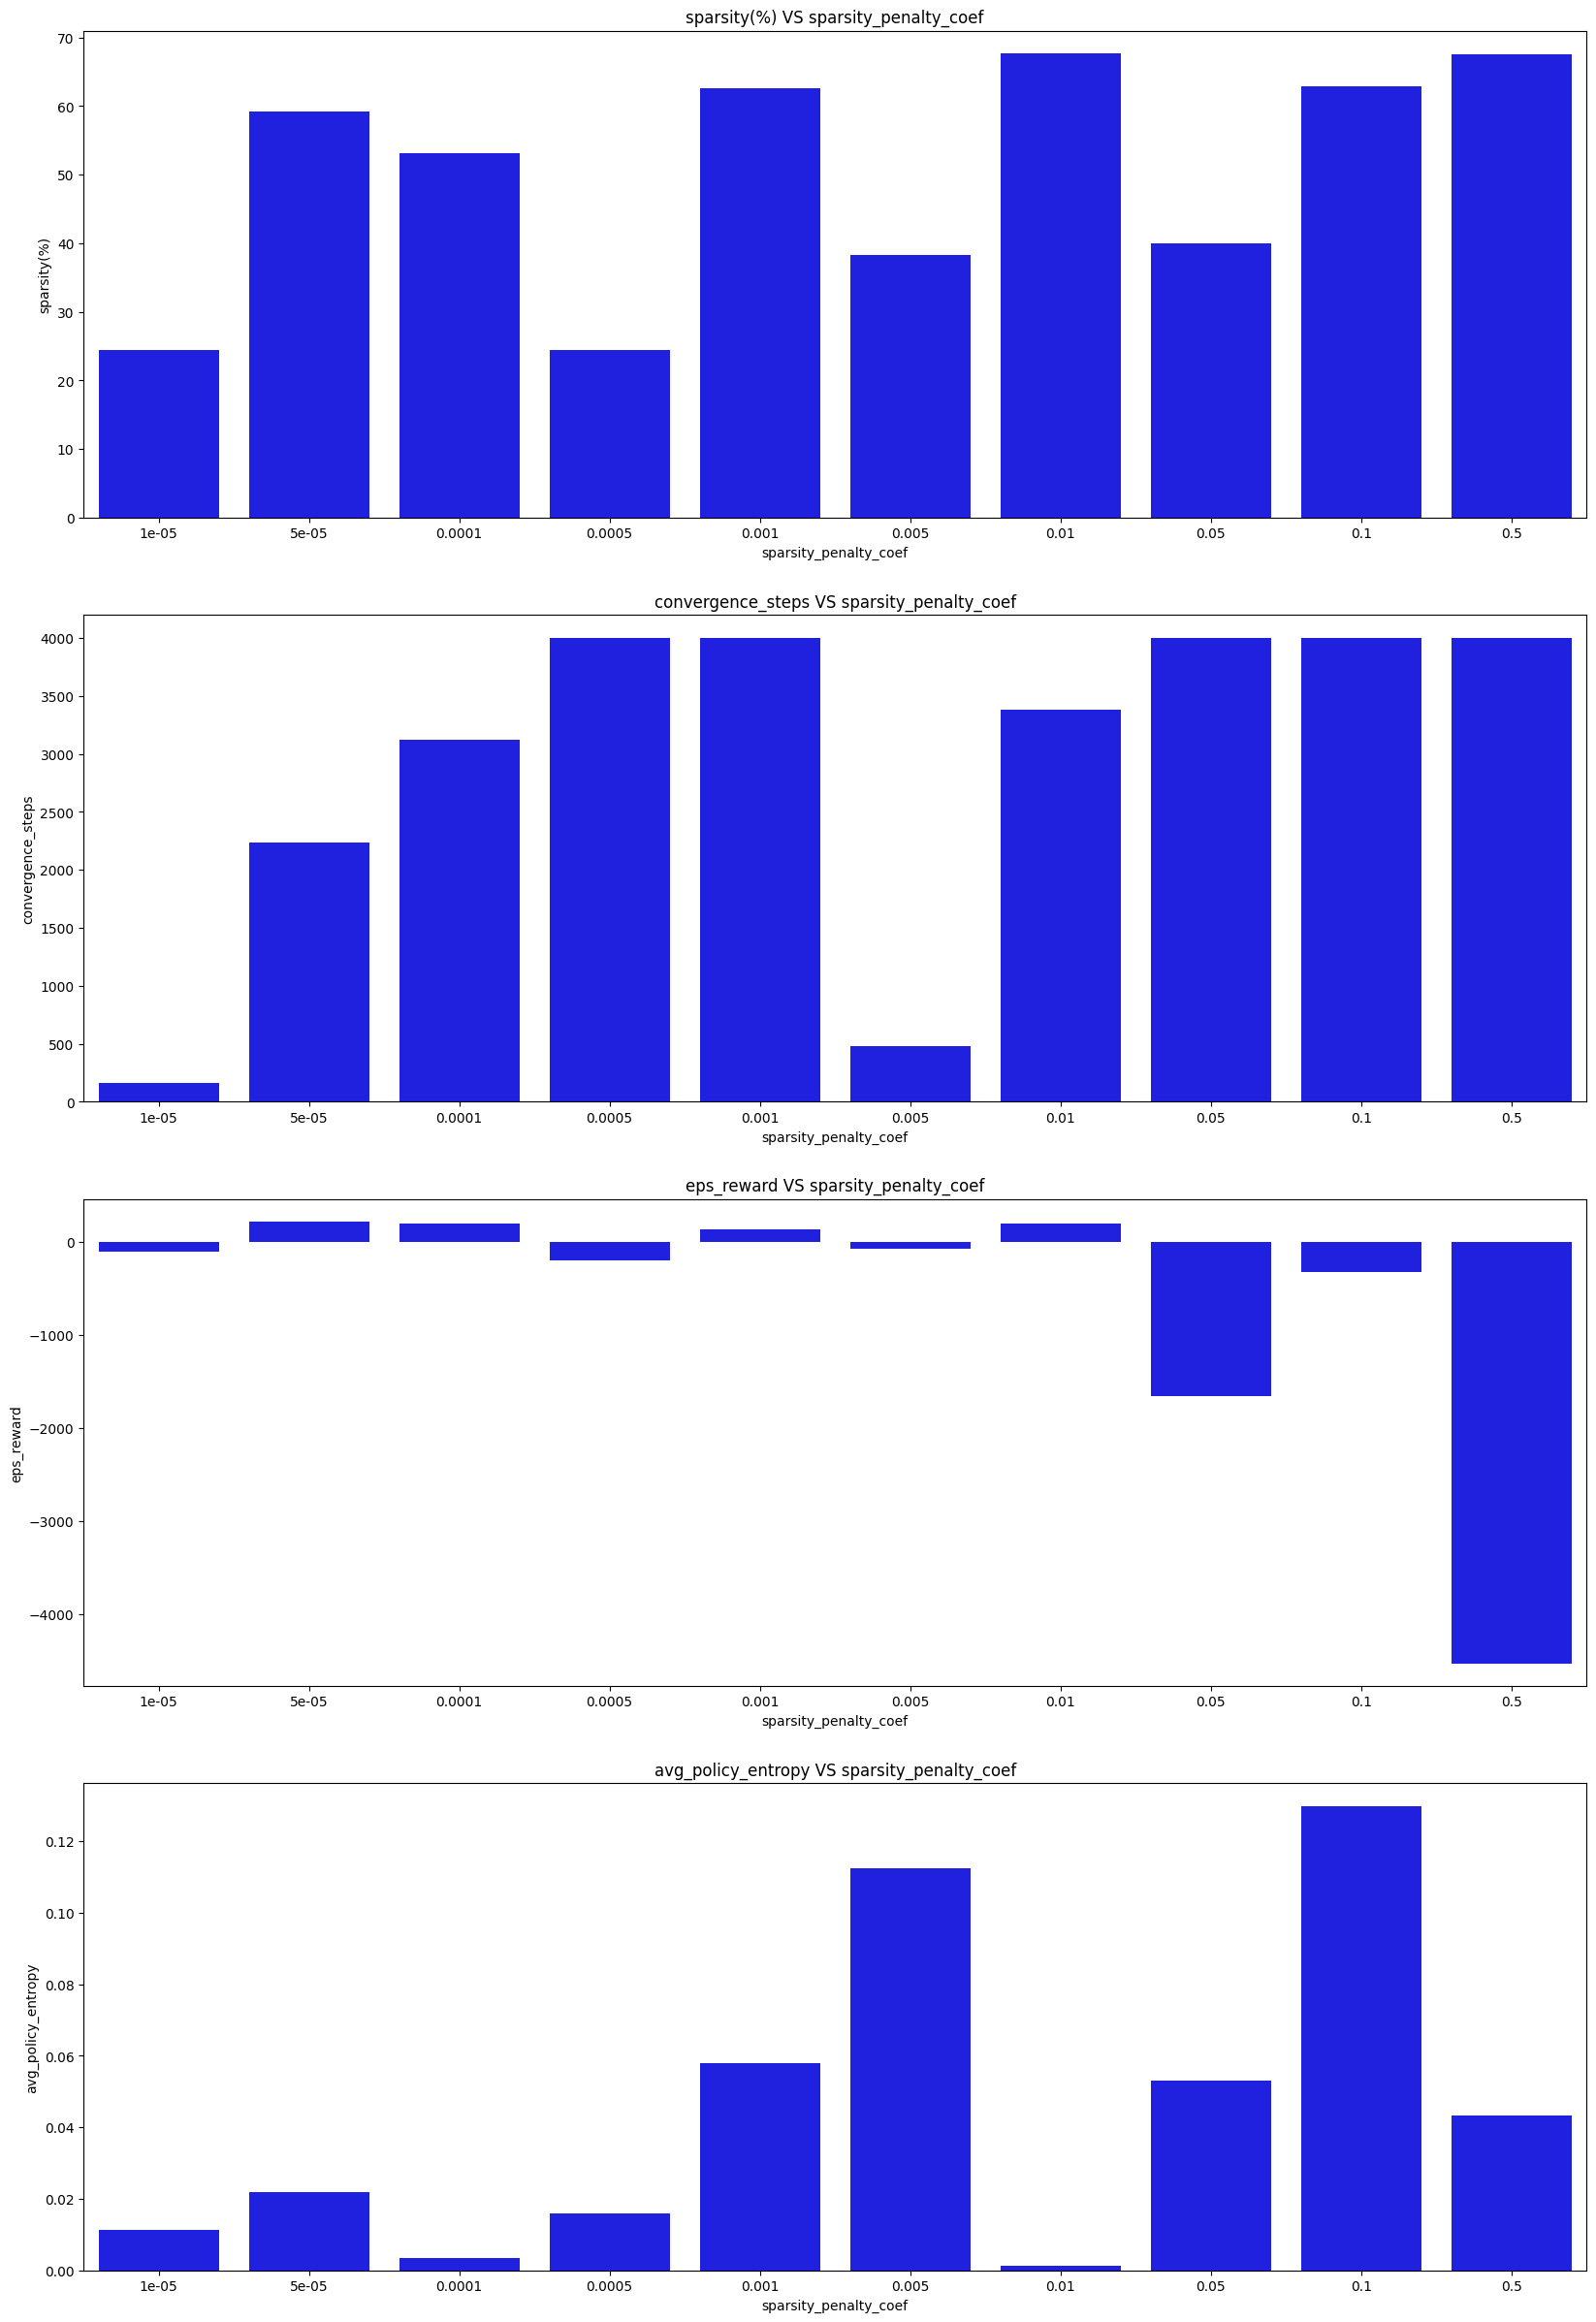

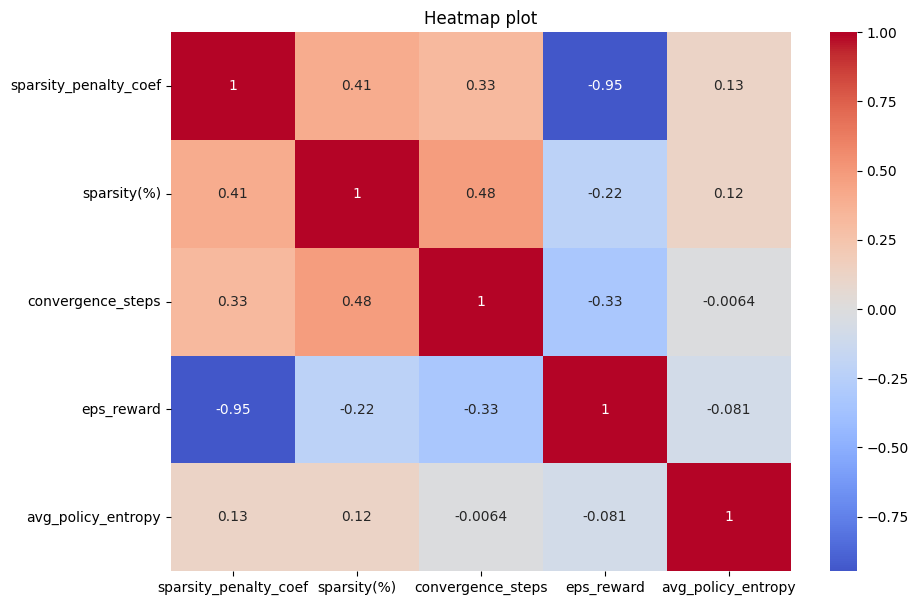

,sparsity_penalty_coef,sparsity(%),convergence_steps,eps_reward,avg_policy_entropy
0,0.00001,24.377441,161,-107.151301,0.011304
1,0.00005,59.158325,2234,223.695888,0.021982
2,0.00010,53.100586,3121,202.897869,0.003431
3,0.00050,24.472046,4000,-198.174732,0.015894
4,0.00100,62.603760,4000,137.414780,0.057814
5,0.00500,38.269043,477,-72.041149,0.112387
6,0.01000,67.614746,3380,197.806616,0.001145
7,0.05000,39.990234,4000,-1662.141497,0.052948
8,0.10000,62.832642,4000,-322.572257,0.129718
9,0.50000,67.474365,4000,-4538.215586,0.043169


In [7]:
result = dict()
result["sparsity_penalty_coef"] = []
result["sparsity(%)"] = []
result["convergence_steps"] = []
result["eps_reward"] = []
result["avg_policy_entropy"] = []

policy_weights_filename = f"{env_name}_PPO_sparse_policy_agent.pth.tar"
best_score = -np.inf
best_model_idx = None

for idx, coef in enumerate(sparsity_penalty_coefs):
    sparse_policy_agent = SparsePolicyNet(observation_space, action_space, hidden_size, sparsity_on_eval=True)
    sparse_policy_agent.to(os.getenv("DEVICE"))
    sparse_value_agent = SparsePolicyNet(observation_space, 1, hidden_size, sparsity_on_eval=True)
    sparse_value_agent.to(os.getenv("DEVICE"))

    sparse_policy_agent.apply(xavier_init_weights)
    sparse_value_agent.apply(xavier_init_weights)

    sparse_policy_optimizer = torch.optim.Adam(sparse_policy_agent.parameters(), lr=policy_lr)
    sparse_value_optimizer = torch.optim.Adam(sparse_value_agent.parameters(), lr=value_lr)

    print(f"Training sparse policy with sparsity coef: {coef}\n")

    weights_filename = f"{idx}_{policy_weights_filename}"
    convergence_steps = run_train(
        sparse_policy_agent, 
        sparse_value_agent, 
        sparse_policy_optimizer, 
        sparse_value_optimizer, 
        weights_filename, 
        plot_performance=True,
        sparse_penalty_coef=coef
    )
    sparse_policy_agent.load_state_dict(torch.load(os.path.join(f"../params/{weights_filename}")))
    eps_reward, avg_policy_entropy = run_evaluation(
        gym.make(env_name, render_mode=RENDER_MODE_ON_EVAL), 
        sparse_policy_agent, 
        verbose=False
    )
    weight_sparsity = sparse_policy_agent.compute_weight_sparsity()[1] * 100
    score = eps_reward + weight_sparsity

    if score > best_score:
        best_score = score
        best_model_idx = idx

    result["sparsity_penalty_coef"].append(coef)
    result["sparsity(%)"].append(weight_sparsity)
    result["convergence_steps"].append(convergence_steps)
    result["eps_reward"].append(eps_reward)
    result["avg_policy_entropy"].append(avg_policy_entropy)

    del sparse_policy_agent, sparse_value_agent, sparse_policy_optimizer, sparse_value_optimizer
    gc.collect()
    torch.cuda.empty_cache()

unwanted_models = [
    f"../params/{i}_{policy_weights_filename}" for i in range(len(sparsity_penalty_coefs)) if i != best_model_idx
]

for i in range(len(sparsity_penalty_coefs)):
    if i == best_model_idx:
        os.rename(f"../params/{i}_{policy_weights_filename}", f"../params/{policy_weights_filename}")
        continue
    os.remove(f"../params/{i}_{policy_weights_filename}")

result = pd.DataFrame(result)
plot_result_dataframe(result, x_axis="sparsity_penalty_coef", figsize=(20, 30))
os.makedirs(results_dir, exist_ok=True)
result.to_csv(os.path.join(results_dir, f"{env_name}_PPO_sparsification_results.csv"), index=False)
result

In [ ]:
with open(os.path.join(results_dir, f"{env_name}_PPO_rewards.json"), "w") as f:
    json.dump(REWARDS_DICT, f, indent=4)